# Writing a custom derivative class

`StableEMRIFisher` computes waveform derivatives with a derivative class, a subclass of `DerivativeBase`. The base class builds the waveform model, sets the reference point and provides finite-difference helpers. A new derivative method only has to implement `compute()`, and passes to SEF through `deriv_type`.

This example writes a derivative class that improves finite differences by Richardson extrapolation, and uses it for FEW's 5PN AAK waveform (`Pn5AAKWaveform`), without the LISA response. It covers:

1. Defining the class.
2. Computing a Fisher matrix over `m1`, `m2` and `a` with it.
3. Computing the same Fisher matrix with SEF's built-in `DirectDerivative`, and comparing the two as covariance ellipses.

Without a noise model or response, SEF uses its default sky-averaged LISA sensitivity curve.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import few
from few.waveform import Pn5AAKWaveform

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.derivatives import DerivativeBase
from stableemrifisher.utils.plot import plot_covariance_ellipses

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Define the derivative class

`compute(param_to_vary, delta, order, kind)` returns the derivative at the reference point, in the `(channels, samples)` layout of the waveform. Here it calls the base-class helper `_finite_difference` (finite differences of the full waveform) at the steps $\delta$ and $\delta/2$. For a stencil of order $n$, the error of each is proportional to $\delta^n$ to leading order, and the combination

$$h' \approx \frac{2^n D(\delta/2) - D(\delta)}{2^n - 1}$$

cancels that term. Two class attributes describe what the class supports: `supports_response = True` allows a LISA response wrapper, and `analytic_params` lists the parameters it differentiates exactly, without a step size. Here that is the distance, since $h \propto 1/d_L$.

In [ ]:
class RichardsonDerivative(DerivativeBase):
    """Finite differences of the full waveform with Richardson extrapolation.

    See https://faculty.washington.edu/finlayso/ebook/bvp/bvp_fd/errors/Richardson.htm
    """

    supports_response = True  # works with a ResponseWrapper
    analytic_params = frozenset({"dist"})  # no step-size search for these

    def compute(self, param_to_vary, delta, order, kind):
        if param_to_vary == "dist":
            return -self.waveform / self.parameters["dist"]  # h is proportional to 1/dist
        coarse = self._finite_difference(param_to_vary, delta, order, kind)
        fine = self._finite_difference(param_to_vary, delta / 2, order, kind)
        return (2**order * fine - coarse) / (2**order - 1)

## Set up StableEMRIFisher with the custom class

The class is passed as `deriv_type`, in place of a name such as `"stable"` or `"direct"`. Without a response, the waveform has two channels, $[h_+, h_\times]$.

In [3]:
T = 0.1  # observation time, years
dt = 10.0  # sampling interval, seconds

sef_kwargs = dict(
    waveform_class=Pn5AAKWaveform,
    waveform_class_kwargs=dict(inspiral_kwargs=dict(err=1e-13)),  # trajectory integrator tolerance
    T=T,
    dt=dt,
    use_gpu=use_gpu,
)

sef = StableEMRIFisher(**sef_kwargs, deriv_type=RichardsonDerivative)

No noise model or response wrapper provided.
Defaulting to the sky-averaged sensitivity curve


## Compute the Fisher matrix

SEF uses the class like any other: for each parameter it tries `Ndelta` step sizes from its default grid and keeps the one where the diagonal Fisher element is most stable. `stats_for_nerds=True` prints the chosen step sizes.

In [4]:
wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=10.0,  # secondary mass, solar masses
    a=0.9,  # primary spin
    p0=9.5,  # initial semi-latus rectum
    e0=0.4,  # initial eccentricity
    xI0=0.5,  # cosine of the initial inclination
    dist=0.1,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # initial polar phase
    Phi_r0=0.0,  # initial radial phase
)

param_names = ["m1", "m2", "a"]

Fisher_richardson = sef(dict(wave_params), param_names=param_names, der_order=4, Ndelta=8, stats_for_nerds=True)
covariance_richardson = np.linalg.inv(Fisher_richardson)

Waveform Generated. SNR: 122.39503481770953
  m1         delta = 2.683e-02   relerr = 2.1e-09   (8 steps)             
  m2         delta = 1.931e-04   relerr = 7.5e-10   (8 steps)              
  a          delta = 1.738e-05   relerr = 3.0e-06   (8 steps)              
Computing Fisher   : 100%|██████████| 3/3 [00:09<00:00,  3.31s/deriv]    
Calculated Fisher is positive-definite.


## Compare with the direct derivative

The same Fisher matrix with SEF's built-in `DirectDerivative` (`deriv_type="direct"`), the class SEF uses by default for this waveform.

In [5]:
sef_direct = StableEMRIFisher(**sef_kwargs, deriv_type="direct")

Fisher_direct = sef_direct(dict(wave_params), param_names=param_names, der_order=4, Ndelta=8, stats_for_nerds=True)
covariance_direct = np.linalg.inv(Fisher_direct)

print(f"{'':3s}  {'Richardson':>11s}  {'direct':>11s}")
for name, s_r, s_d in zip(
    param_names, np.sqrt(np.diag(covariance_richardson)), np.sqrt(np.diag(covariance_direct))
):
    print(f"{name:3s}  {s_r:11.3e}  {s_d:11.3e}")

No noise model or response wrapper provided.
Defaulting to the sky-averaged sensitivity curve
Waveform Generated. SNR: 122.39503481770953
  m1         delta = 5.179e-03   relerr = 8.1e-09   (8 steps)             
  m2         delta = 3.728e-05   relerr = 6.2e-11   (8 steps)              
  a          delta = 3.355e-06   relerr = 3.7e-05   (8 steps)              
Computing Fisher   : 100%|██████████| 3/3 [00:05<00:00,  1.70s/deriv]    
Calculated Fisher is positive-definite.
      Richardson       direct
m1     9.639e-01    9.639e-01
m2     1.198e-03    1.198e-03
a      8.825e-06    8.825e-06


## Covariance ellipses

`plot_covariance_ellipses` draws the 2σ ellipses of both covariance matrices on the same axes.

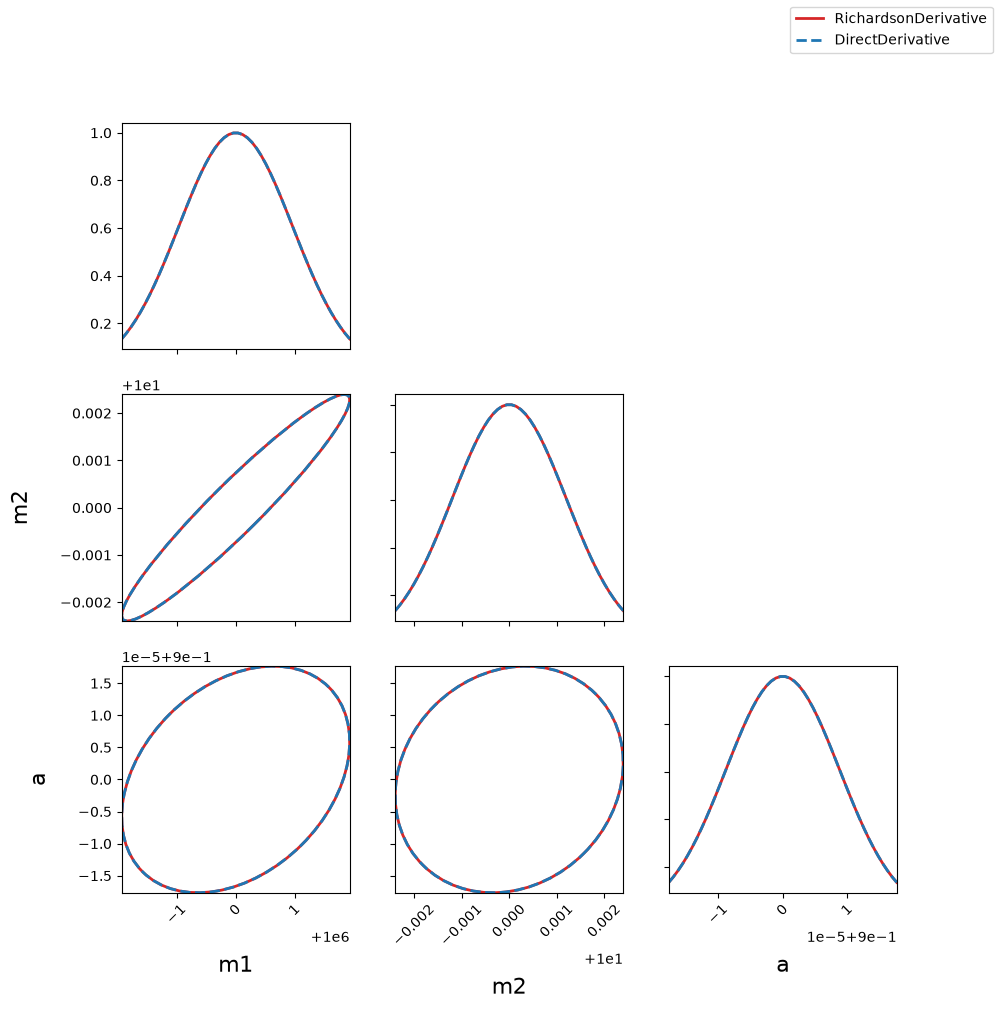

In [6]:
n = len(param_names)
fig, axs = plt.subplots(n, n, figsize=(10, 10))

for covariance, color, ls in [
    (covariance_richardson, "tab:red", "-"),
    (covariance_direct, "tab:blue", "--"),
]:
    plot_covariance_ellipses(
        covariance,
        param_names=param_names,
        wave_params=wave_params,
        fig=fig,
        axs=axs,
        ellipse_kwargs=dict(facecolor="none", edgecolor=color, ls=ls, lw=2),
        line_kwargs=dict(color=color, ls=ls, lw=2),
    )

fig.legend(
    handles=[
        plt.Line2D([], [], color="tab:red", lw=2, label="RichardsonDerivative"),
        plt.Line2D([], [], color="tab:blue", ls="--", lw=2, label="DirectDerivative"),
    ],
    loc="upper right",
)
plt.show()

## What this shows

A new derivative method takes one `compute()` method on top of `DerivativeBase`, and works with SEF's step-size search and Fisher matrix through `deriv_type`. For this source, the Richardson-extrapolated and direct finite differences give matching Fisher matrices. Because the class sets `supports_response = True`, the same class also works through the LISA response (see `fisher_matrix_with_response.ipynb` for the set-up).